In [5]:
## Clone your forked repository to Colab ##

## Specify your GitHub username:
user_name <- "wasifmostofa36"

## Specify the repository:
repo_name <- "STAT-7110-Quality-Control"

## Set the web address to your forked repository:
repo_address <- paste0(
  "https://github.com/",
  user_name,
  "/",
  repo_name,
  ".git"
)

## Check to see if repo is already cloned to Colab, and if not, clone repo:
if (!dir.exists(repo_name)) {
  system(paste("git clone", repo_address))
} else {
  print("Repository already cloned to Colab.")
}
## Set working drive to today's lecture:

setwd("STAT-7110-Quality-Control//Assignments//HW4")

## Homework 4 - Analysis Using Hotelling's $T^2$ and Multiple Stream Process Control Charts
### Dr. Austin Brown
### Kennesaw State University

**DUE: November 20, 2026 via D2L**

## Instructions:

You are the director of The Owl's Nest, a psychological services program at a local university that employs a team of four Clinical Psychology PhD students to offer counseling services to the campus community at a steep discount. When a new client comes in, they commit to biweekly sessions for at least one semester. At the start of each session, the client completes a brief survey assessing depressive symptoms using Likert-scale items (e.g., "How much do you agree with this statement, on a scale from 1 (strongly disagree) to 5 (strongly agree)?"). The total score ranges from 20 to 100, with higher scores indicating more severe depressive symptoms.

If a counselor's client scores begin trending upward over time, that may indicate a need for you, as the director, to step in -- whether by providing additional training and supervision, or by referring a client to a higher level of care. Because all four counselors work in the same training program, share office space and supervision, and often see clients during the same high-stress points in the academic calendar (midterms, finals), you suspect their clients' scores may be correlated with one another from week to week, rather than behaving as four completely independent processes.

To monitor this, you perform an initial Phase I analysis, jointly monitoring the scores of all four counselors across the 16-week fall semester, taking a sample of 5 clients per week for each counselor. After confirming statistical control, you'll monitor the subsequent 16-week spring semester (Phase II) to determine whether anything has changed.

## Key Specifications

| Quantity | Value |
|---|---|
| Quality characteristic | Total depressive-symptom survey score (20-100 scale) |
| Number of counselors (streams) | 4 |
| Clients sampled per counselor per week (n) | 5 |
| Phase I weeks (m) | 16 (fall semester) |
| Phase II weeks (m) | 16 (spring semester) |
| Control Chart for Each Stream design value | $L = 3.46$ |

## Define & Measure

### Q1: Briefly describe the purpose of this analysis

As the director of the Owl's Nest, we are to perform an initial Phase I analysis, jointly monitoring the scores of all four counselors across the 16-week fall semester, taking a sample of 5 clients per week for each counselor. After confirming statistical control, you'll monitor the subsequent 16-week spring semester (Phase II) to determine whether anything has changed.

### Q2: Identify the quality characteristic being monitored, and classify its measurement scale. Why might it be reasonable to suspect that the four counselors' weekly scores are correlated with one another, rather than fully independent?
It is reasonable to suspect correlation because all four counselors' clients share the same outside influences that can move scores up or down in the same week due to shared training they recieved to derive the scores. Also since they are in a similar environment, that could also potentially correlate the scores.

### Q3: Given your answer to Q2, briefly explain why it might be reasonable to treat this scenario as a **multivariate process** (suggesting a Hotelling's $T^2$ chart) rather than a **multiple stream process** (suggesting the Control Chart for Each Stream technique). Under what different assumption would the opposite framing make more sense?
In Q2, we suspected that the four counselors' weekly scores are correlated because they share similar training work environment. The lecture notes say this assumption is what separates the two approaches. Multivariate control charts such as Hotelling's T² are meant for "jointly monitoring several processes when we assume some degree of correlation between them". Multiple stream process charts, by contrast, "generally assume independence between streams".

Treating the counselors as a multivariate process is reasonable here for two reasons: It captures joint patterns and it controls the false alarm rate.

## Analyze

### Q4: Read the Phase I data (`Counselling_PhaseI.xlsx`) into R as a list, one data frame per counselor (HINT: use `qcc::mqcc`, and make sure to remove the `Week` column from each data frame, possibly using `lapply`). Construct a Phase I Hotelling's $T^2$ chart. Do we have evidence of statistical control? Why or why not?

[1] "Counselor1" "Counselor2" "Counselor3" "Counselor4"

List of 1
 $ Counselor1: tibble [16 × 5] (S3: tbl_df/tbl/data.frame)
  ..$ Client1: num [1:16] 40 52.4 43.7 64.2 40.5 ...
  ..$ Client2: num [1:16] 46.5 51.3 43 44.7 43.9 ...
  ..$ Client3: num [1:16] 38.3 45.6 50.6 50.5 54.4 ...
  ..$ Client4: num [1:16] 57.8 29.1 49.5 45.2 32.8 ...
  ..$ Client5: num [1:16] 47.6 50 39.5 39 49.8 ...


[1] 0.01075634

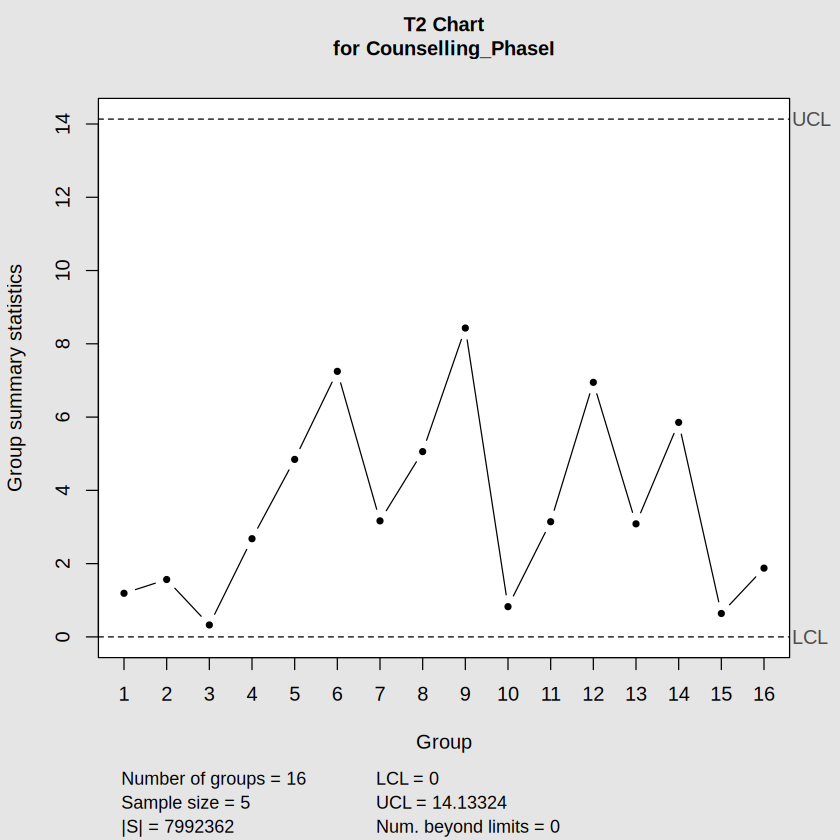

In [8]:
## Q4 Code ##

## Load the Libraries ##

#install.packages("tidyverse")
#install.packages("readxl")
#install.packages("qcc")

library(tidyverse)
library(readxl)
library(qcc)

## Read in Phase I Counselling Data as List ##

## Note, each counselor's data is in a separate sheet of the Excel file, so we will
## read in each sheet as a separate data frame and store them in a list. ##

## Get Sheet Names ##

sn <- excel_sheets("Counselling_PhaseI.xlsx")
sn

names(Counselling_PhaseI) <- paste("Counselor",1:4,sep="")


Counselling_PhaseI <- lapply(sn,FUN=function(x){

  d <- read_xlsx("Counselling_PhaseI.xlsx",sheet=x) %>%
    dplyr::select(-`Week`)

  return(d)

})

names(Counselling_PhaseI) <- paste("Counselor",1:4,sep="")

Counselling_PhaseI["Counselor1"] |> glimpse()

## Use mqcc to Plot the Phase I Chart ##

t2 <- mqcc(Counselling_PhaseI,type='T2')

## Note default alpha = 1 - (1 - 0.0027)^p and in this case p = 4 ##

1 - (0.9973)^4

### Q5: Report the sample mean vector and sample variance-covariance matrix from Q4.

In [11]:
## Q5 Code ##
## Notice, t2 contains the estimated mean vector and v-cov matrix ##

t2$center

t2$cov

Counselor1 Counselor2 Counselor3 Counselor4 
  45.34275   46.00288   45.28650   45.45975

,Counselor1,Counselor2,Counselor3,Counselor4
Counselor1,64.94685,25.20394,18.73784,28.36822
Counselor2,25.20394,63.96758,30.76070,26.36930
Counselor3,18.73784,30.76070,67.29034,14.95226
Counselor4,28.36822,26.36930,14.95226,60.67095


### Q6: Read the Phase II data (`Counselling_PhaseII.xlsx`) into R the same way. Using the mean vector and covariance matrix from Q5, construct a Phase II Hotelling's $T^2$ chart. Do we still have evidence of statistical control? If not, generate individual univariate Shewhart $\bar{X}$ and $s$ charts (using the appropriate mean and standard deviation from Phase I) to determine which counselor(s) may have out-of-control scores.

[1] "Counselor1" "Counselor2" "Counselor3" "Counselor4"

$Counselor1
[1] 46.16112

$Counselor2
[1] 44.43162

$Counselor3
[1] 59.6185

$Counselor4
[1] 44.552

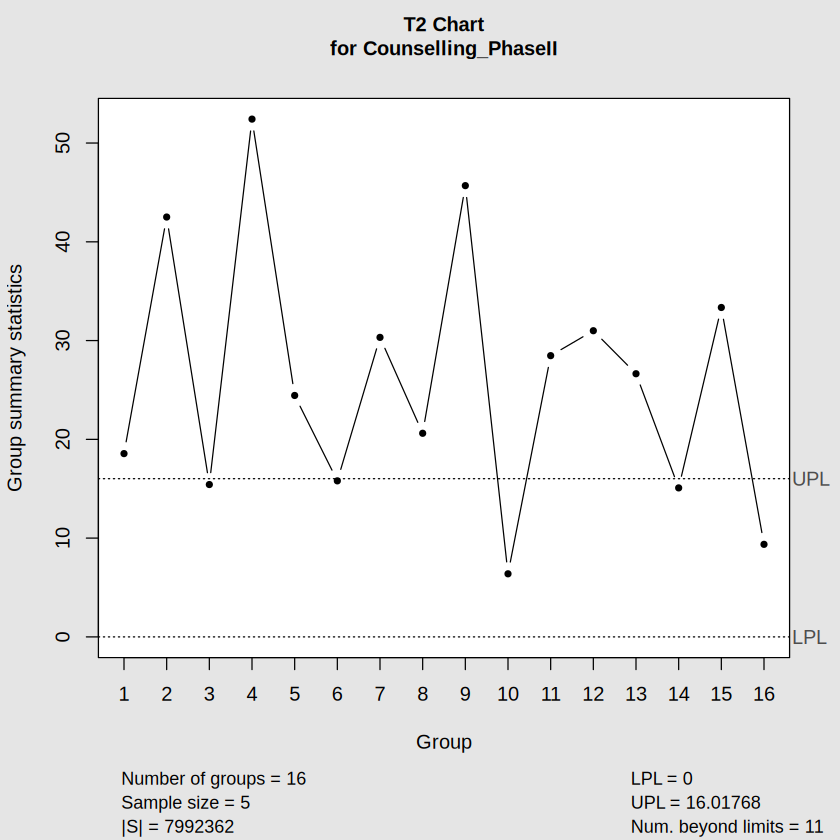

In [15]:
## Q6 Code ##

## Read in Phase II Counselling Data as List ##

sn2 <- excel_sheets("Counselling_PhaseII.xlsx")
sn2

Counselling_PhaseII <- lapply(sn2,FUN=function(x){

  d <- read_xlsx("Counselling_PhaseII.xlsx",sheet=x) %>%
    dplyr::select(-`Week`)

  return(d)

})

names(Counselling_PhaseII) <- paste("Counselor",1:4,sep="")

## Use mqcc to Plot the Phase II Chart! ##

p2 <- mqcc(Counselling_PhaseII,type="T2",
           center=t2$center,
           cov=t2$cov,
           limits=F,pred.limits=T,
           plot=T)

## What is the new mean vector? ##

lapply(Counselling_PhaseII,FUN=function(x){

  return(mean(rowMeans(x)))

})

No, we no longer have evidence of statistical control. Using the Phase I mean vector and covariance matrix from Q5, the Phase II Hotelling's T² chart shows 11 of the 16 spring-semester weeks (weeks 1, 2, 4, 5, 7, 8, 9, 11, 12, 13, and 15) plotting above the UCL of 16.02. This may suggest a shift that occurred between the fall and spring semesters rather than a gradual drift.

The Phase II mean scores by counselor are 46.16 (Counselor 1), 44.43 (Counselor 2), 59.62 (Counselor 3), and 44.55 (Counselor 4). Counselor 3's average is noticeably higher than the others, which suggests Counselor 3 may be the source of the signal.

We will follow up with individual X̄ and s charts for each counselor.

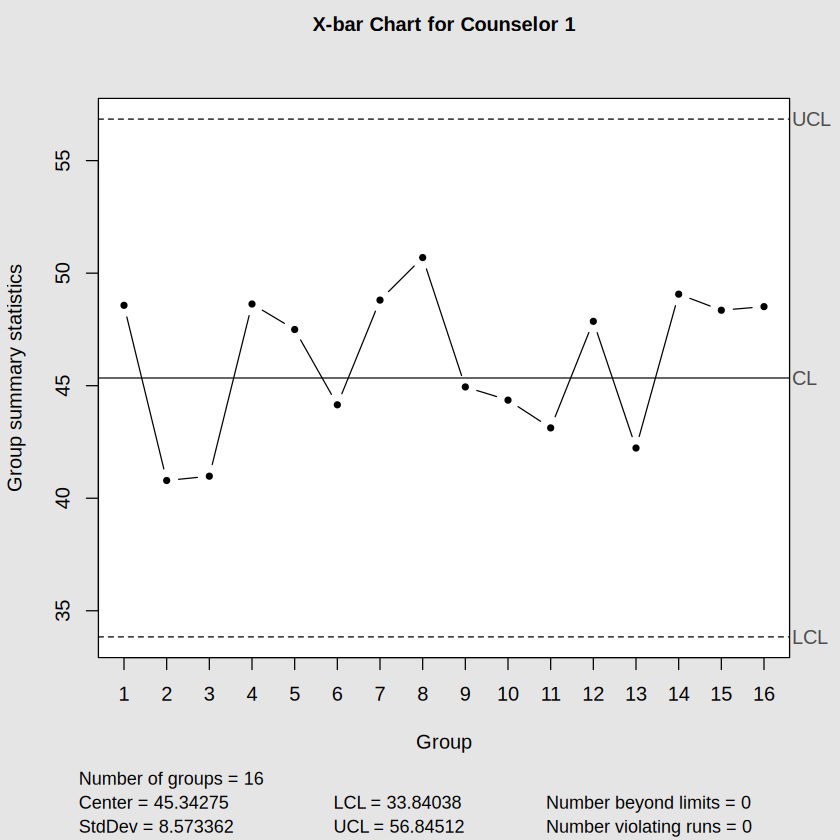

[1] "Counselor 1 x-bar beyond limits:"
integer(0)
[1] "Counselor 1 s beyond limits:"
integer(0)


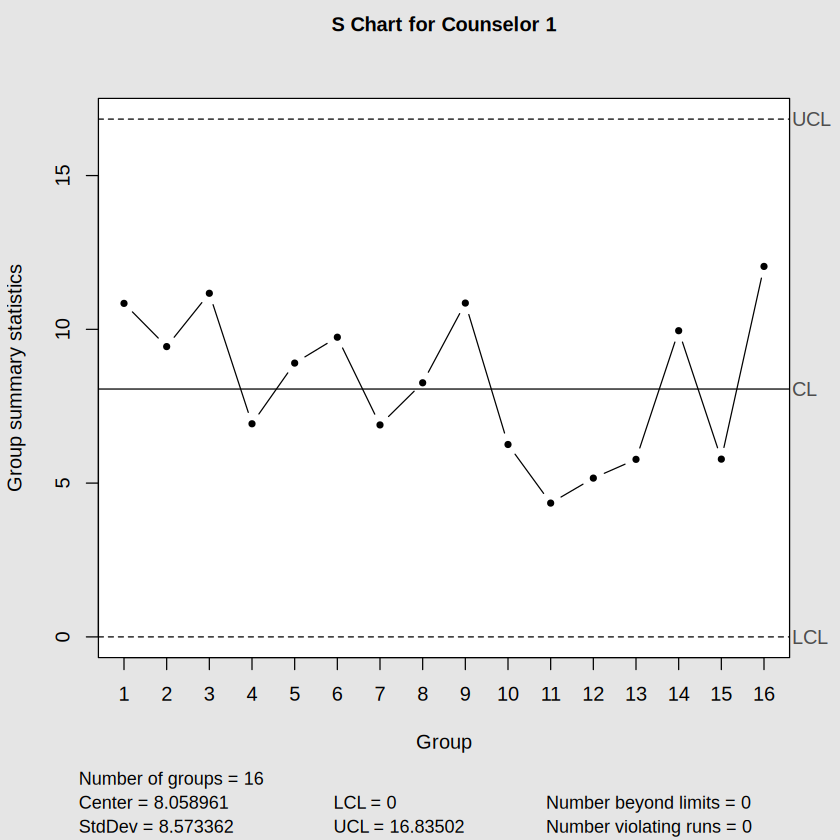

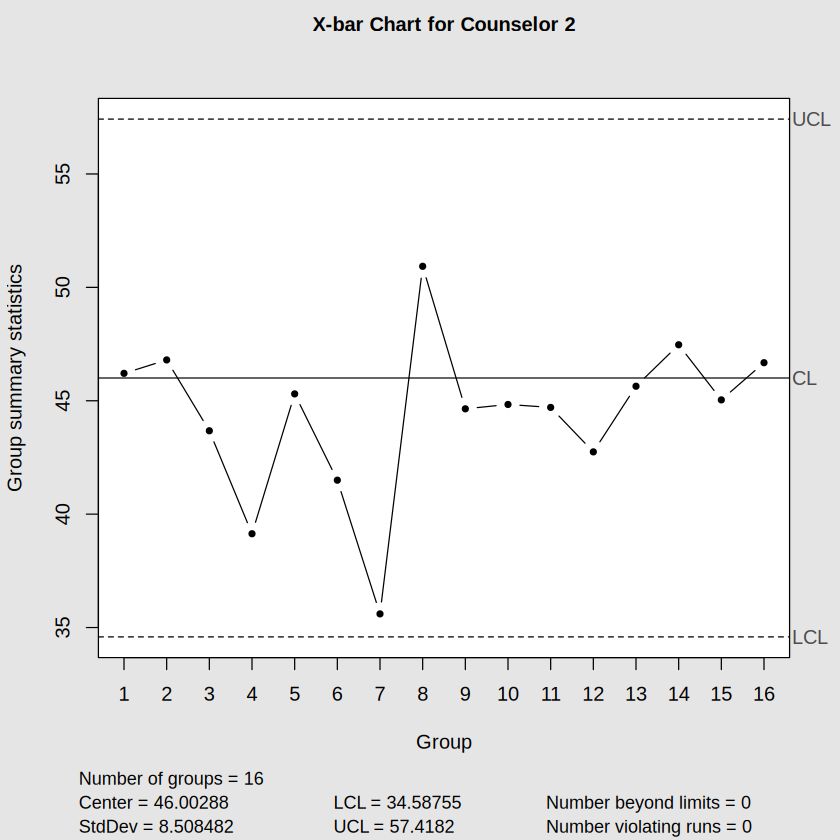

[1] "Counselor 2 x-bar beyond limits:"
integer(0)
[1] "Counselor 2 s beyond limits:"
integer(0)


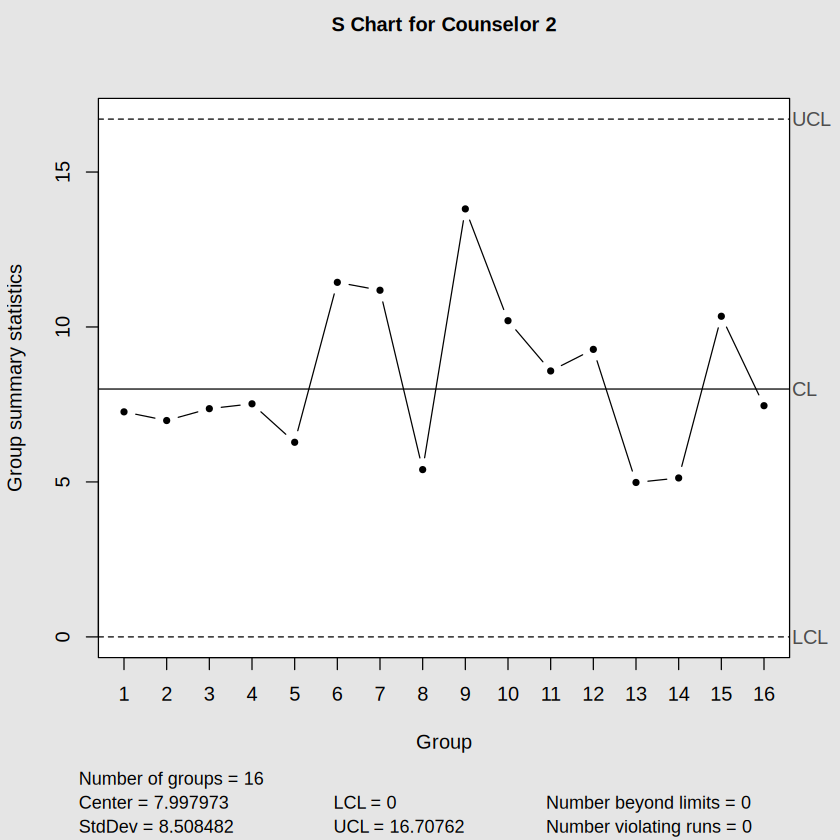

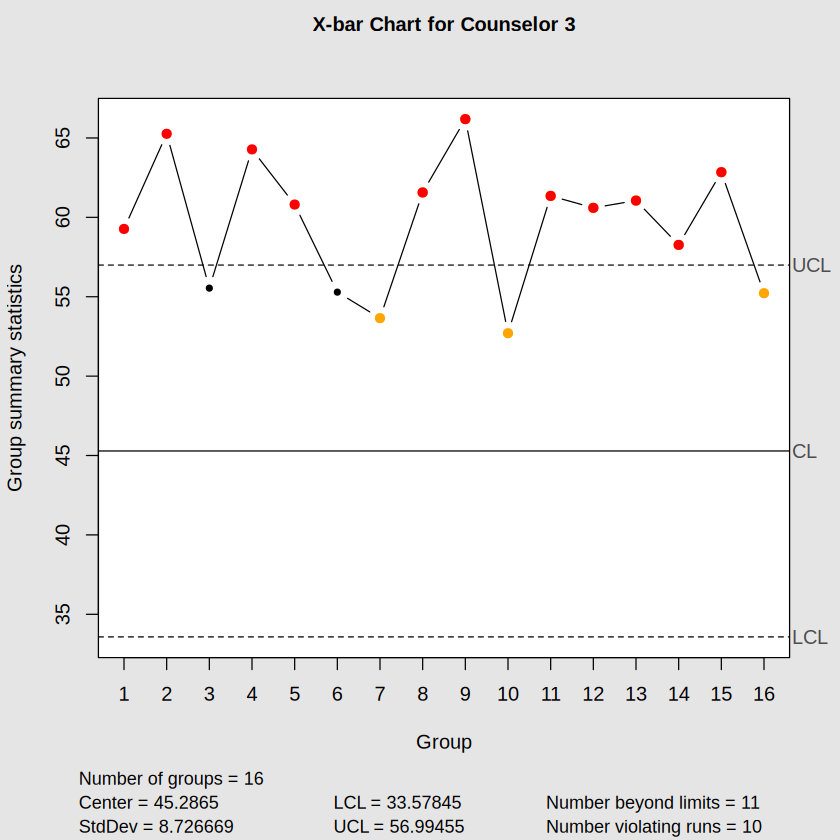

[1] "Counselor 3 x-bar beyond limits:"
 [1]  1  2  4  5  8  9 11 12 13 14 15
[1] "Counselor 3 s beyond limits:"
[1] 9


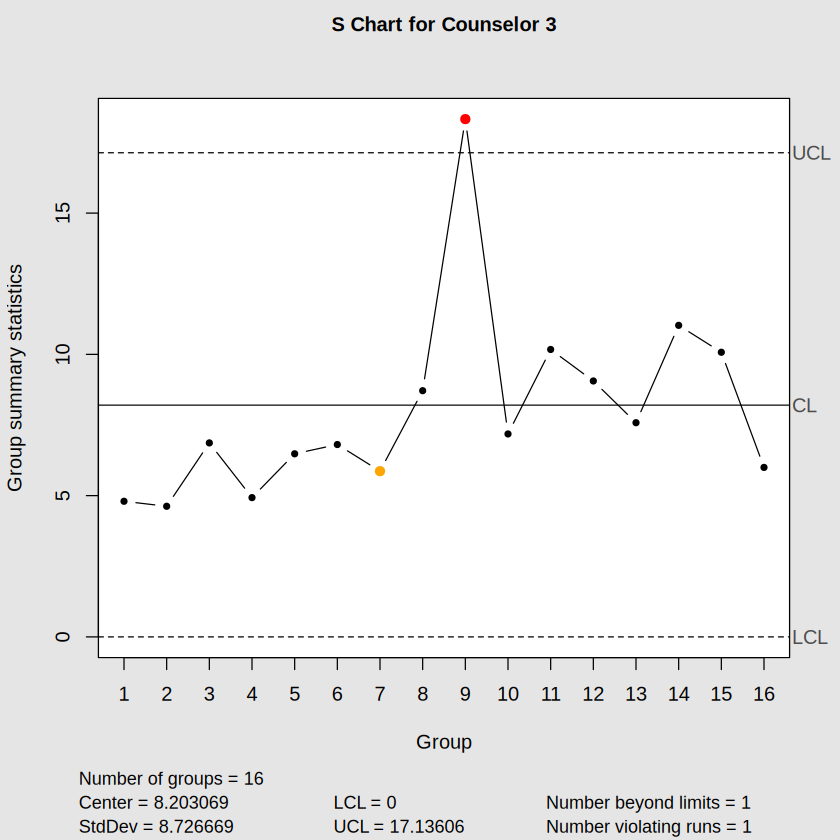

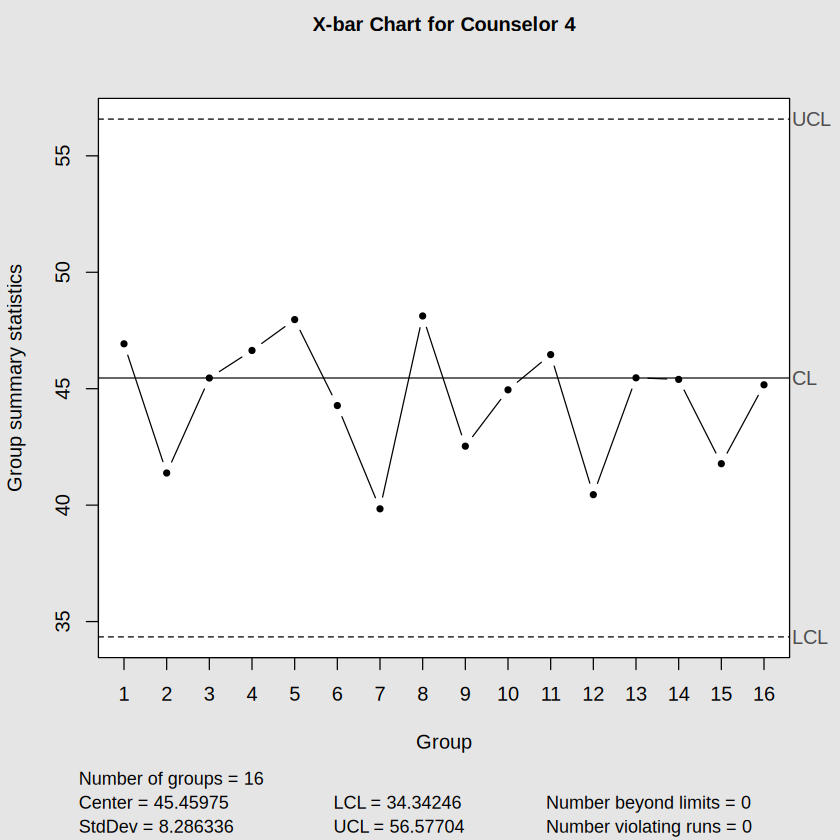

[1] "Counselor 4 x-bar beyond limits:"
integer(0)
[1] "Counselor 4 s beyond limits:"
integer(0)


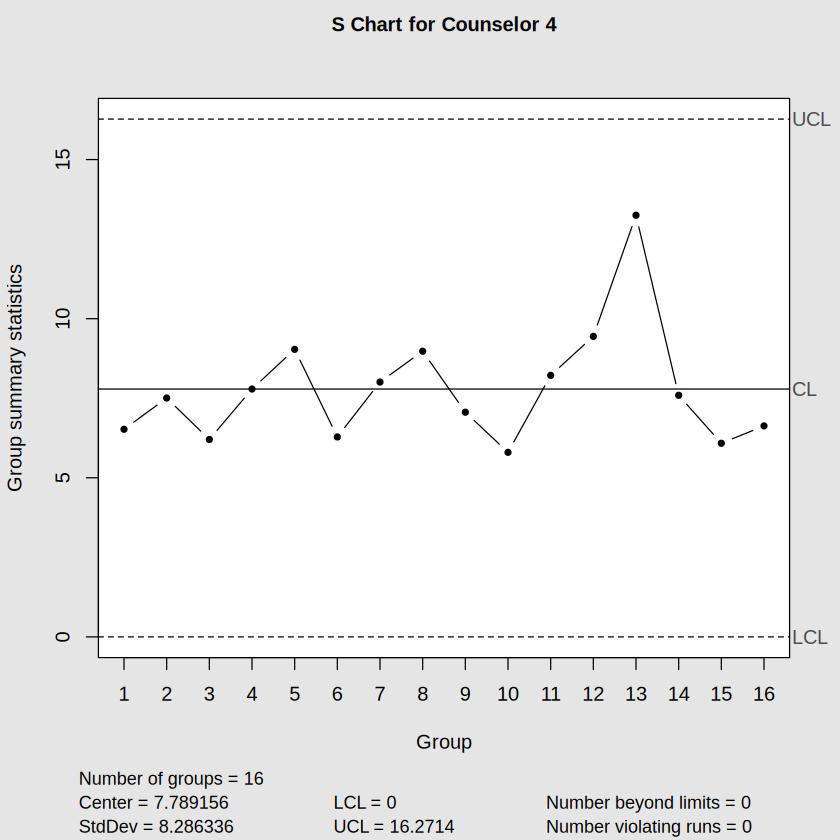

In [16]:
## Post-hoc analysis: individual x-bar & s charts using Phase I estimates ##

## c4 for n = 5 is 0.9400 ##

c4 <- 0.9400

for(i in 1:4){

  ## Phase I mean and sd for counselor i ##
  center_i <- t2$center[i]
  sigma_i <- sqrt(t2$cov[i,i])/c4

  ## Phase II x-bar chart ##
  xbar_i <- qcc(Counselling_PhaseII[[i]],
                type="xbar",
                center=center_i,
                std.dev=sigma_i,
                title=paste("X-bar Chart for Counselor",i),
                plot=TRUE)

  ## Phase II s chart ##
  s_i <- qcc(Counselling_PhaseII[[i]],
             type="S",
             center=c4*sigma_i,
             std.dev=sigma_i,
             title=paste("S Chart for Counselor",i),
             plot=TRUE)

  ## Print any weeks beyond the limits ##
  print(paste("Counselor",i,"x-bar beyond limits:"))
  print(xbar_i$violations$beyond.limits)
  print(paste("Counselor",i,"s beyond limits:"))
  print(s_i$violations$beyond.limits)

}

**Counselors 1, 2, and 4** remain in statistical control. Their X̄ and s charts show no points beyond the limits and no violating runs, and their Phase II averages (46.16, 44.43, and 44.55) are close to their Phase I centers (45.34, 46.00, and 45.46).

**Counselor 3 is out of control.**
- **Mean (X̄ chart):** 11 of 16 weeks (weeks 1, 2, 4, 5, 8, 9, 11, 12, 13, 14, and 15) plot above the UCL of 56.99. Every Phase II week falls above the Phase I center line of 45.29, which also triggers runs-rule violations. Counselor 3's average client score rose from 45.29 in the fall to 59.62 in the spring, an increase of about 14.3 points.

This confirms that the multivariate signal is driven by Counselor 3, whose clients' depressive-symptom scores increased substantially and stayed high throughout the spring semester.

### Q7: What is the benefit of using a multivariate control chart over several separate univariate control charts? What is one limitation?

**Benefit:** A multivariate control chart such as Hotelling's T² monitors all four counselors in a single chart with one overall false alarm rate. It can detect unusual joint patterns that look normal on each counselor's individual chart.

**Limitation:** Combining all the information into one plotting statistic loses detail about what is actually happening in the process.This makes post-hoc analysis a necessary step and isolating the root cause can become a real investigation.

## Improve

### Q8: Based on your findings in Q6, briefly describe what intervention(s) you, as the director, might reasonably take regarding the counselor(s) flagged as out of control.

Only Counselor 3 was flagged as out of control, so any intervention should focus there. We should first try to understand the cause of why the score rose by 14 points. Based on that, we could reccomend further training on the counselor.

## Control

### Q9: It is reasonable to assume that this same monitoring situation could also be conceptualized as a **multiple stream process (MSP)** -- that is, treating the four counselors as independent, parallel processes rather than a single correlated multivariate one. Perform the same Phase I analysis as before, but using the Control Chart for Each Stream MSP technique ($L = 3.46$). Do we have evidence of statistical control?

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependency ‘miscTools’


Loading required package: miscTools



[1] "Counselor1" "Counselor2" "Counselor3" "Counselor4"

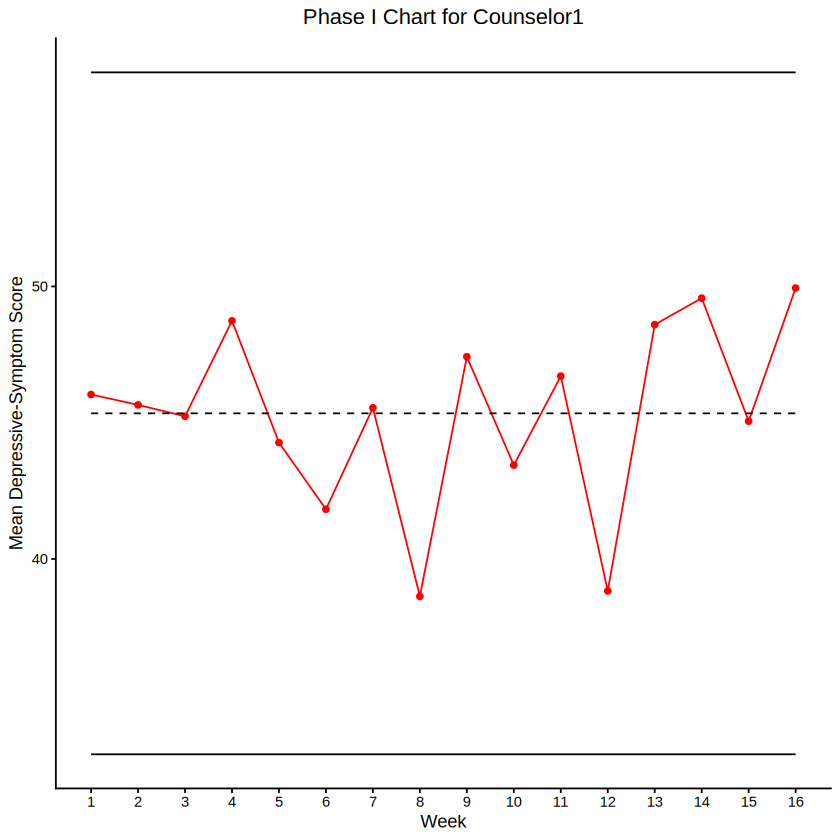

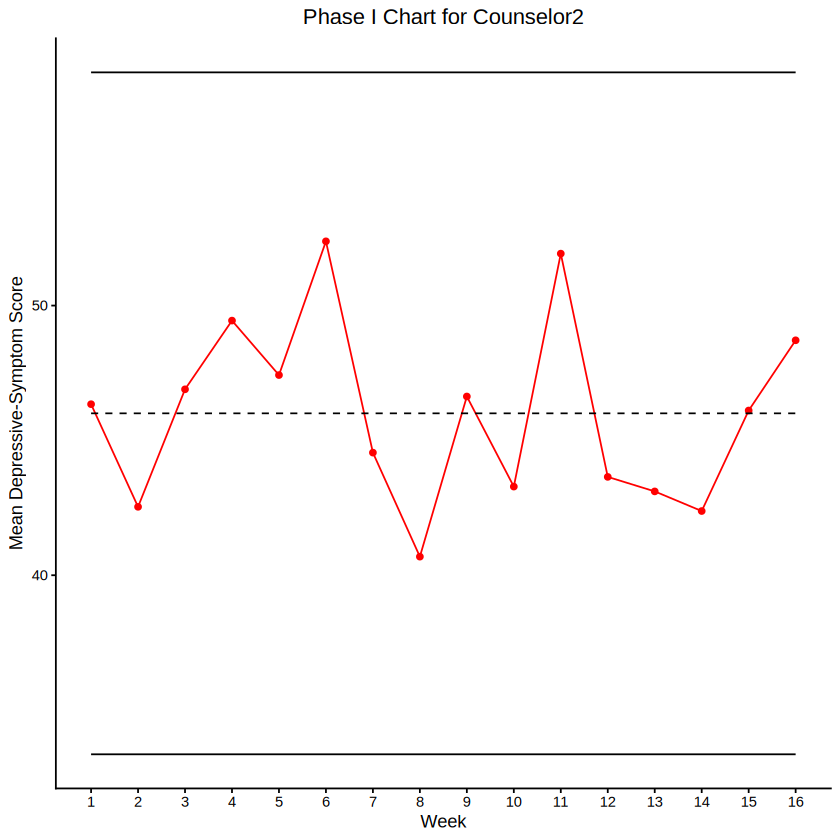

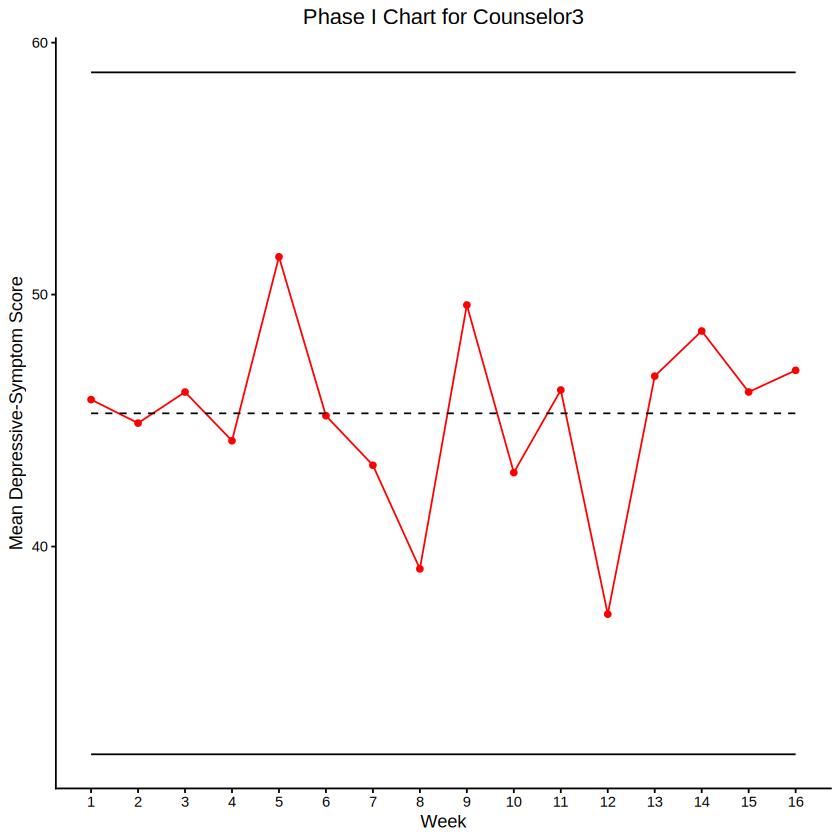

Week
<int>


Week
<int>


Week
<int>


Week
<int>


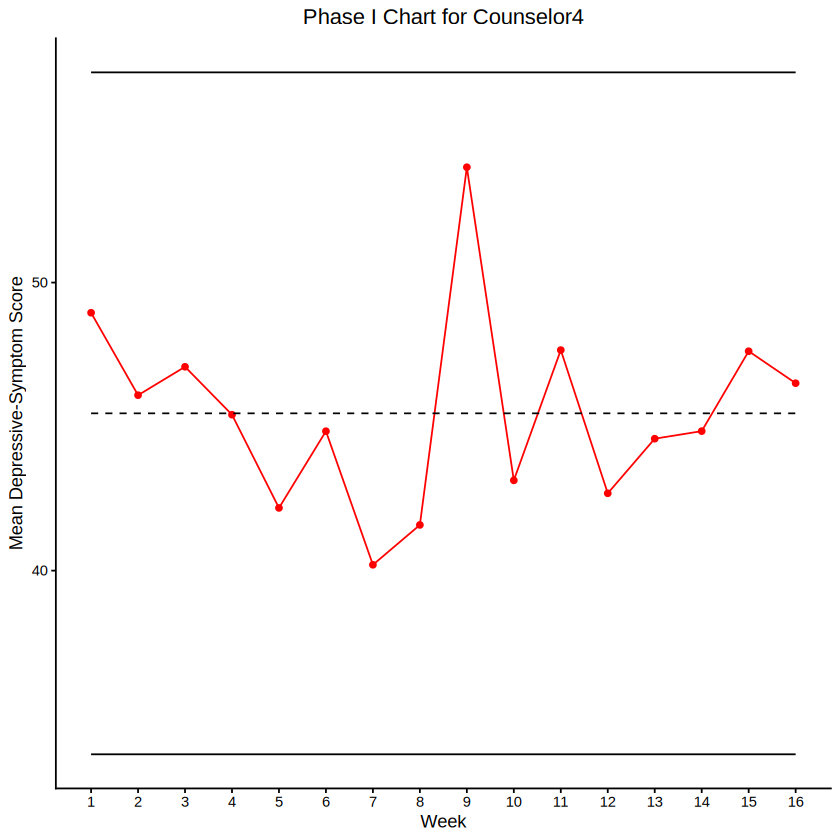

In [18]:
## Q9 Code ##
install.packages("IQCC")
library(IQCC)

sn <- excel_sheets("Counselling_PhaseI.xlsx")
sn

p1 <- lapply(sn,FUN=function(x){

  d <- read_xlsx("Counselling_PhaseI.xlsx",sheet=x) %>%
    dplyr::select(-`Week`)

  return(d)

})

names(p1) <- paste("Counselor",1:4,sep="")

## Now, p1 is a list where each element of the list is a dataframe --
## one for each counselor ##

## Calculate Means & Ranges ##

samp_list <- lapply(names(p1),FUN=function(nm){

  x <- p1[[nm]]

  df <- tibble(Means = rowMeans(x),
               Ranges =
                 apply(x,1,FUN=function(x){

                   max(x) - min(x)

                 }),
               Counselor = nm,
               Week = seq(1,16))

  return(df)

})

names(samp_list) <- names(p1)

## Calculate Control Limits & Plot Charts ##


d2 <- d2(5)

L <- 3.46

## L = 3.46 is the design value given in the assignment's Key Specifications table ##

cfes <- lapply(samp_list,FUN=function(x){

  xdbar <- mean(x$Means)

  rbar <- mean(x$Ranges)

  UCL <- xdbar + L*rbar/(d2*sqrt(5))

  LCL <- xdbar - L*rbar/(d2*sqrt(5))

  p1_chart <- x |>
    ggplot(aes(x=Week,y=Means)) +
    geom_point(color='red') + geom_line(color='red') +
    geom_line(aes(y=UCL),color='black') +
    geom_line(aes(y=LCL),color='black') +
    geom_line(aes(y=xdbar),color='black',linetype='dashed') +
    labs(x = "Week", y = "Mean Depressive-Symptom Score",
         title = paste("Phase I Chart for ",unique(x$Counselor),sep="")) +
    theme_classic()  +
    theme(plot.title=element_text(hjust=0.50)) +
    scale_x_continuous(breaks = seq(1,16))

  info <- list(Center = xdbar,
               Limits = c(LCL,UCL),
               Violations = x |>
                 filter(Means > UCL | Means < LCL) |>
                 select(Week))

  print(p1_chart)

  return(info)

})

## So how can we know if any of our points are OOC? ##

cfes[[1]]

cfes[[2]]

cfes[[3]]

cfes[[4]]

Yes, we have evidence of statistical control. No points fall beyond the limits for any counselor.

### Q10: Perform Phase II analysis using the Control Chart for Each Stream MSP technique. Do we still have evidence of statistical control? If not, which stream(s) (i.e., counselors) may be causing the out-of-control point(s)?

[1] "Counselor1" "Counselor2" "Counselor3" "Counselor4"

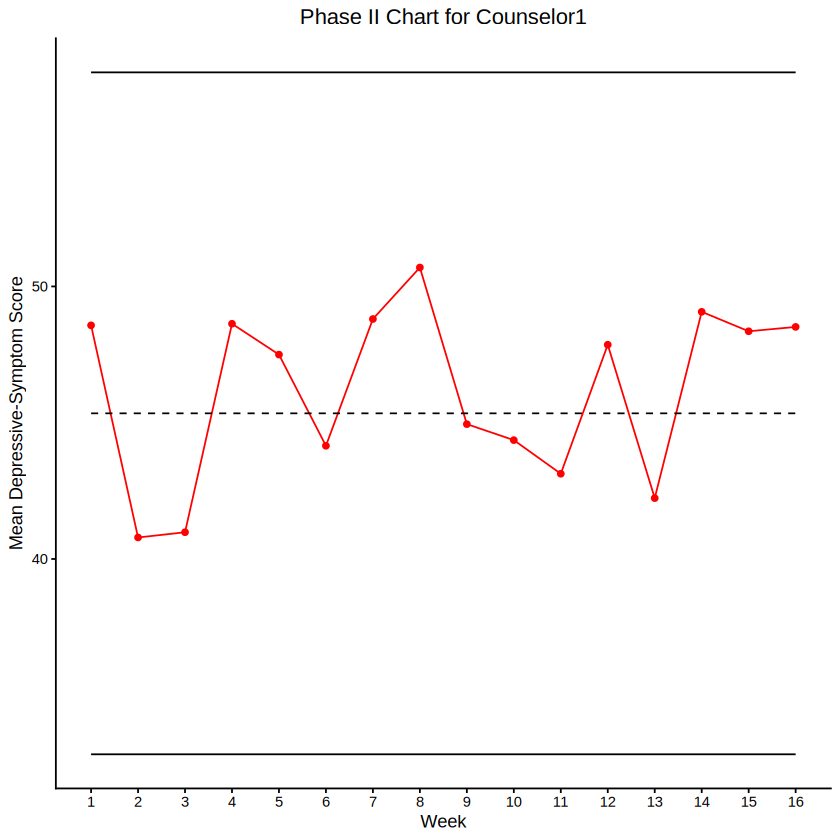

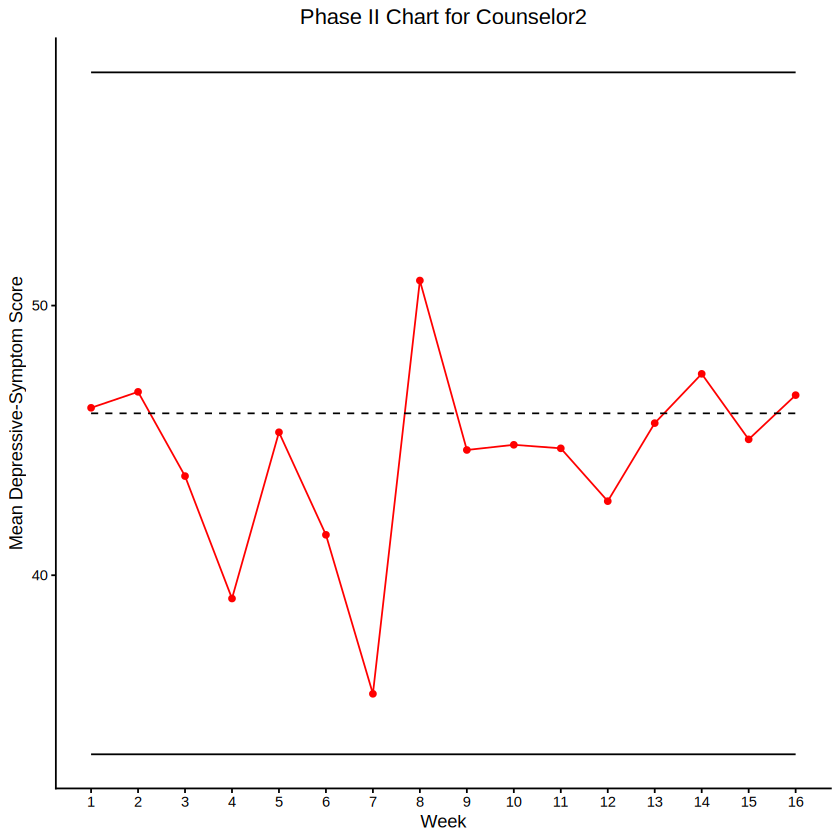

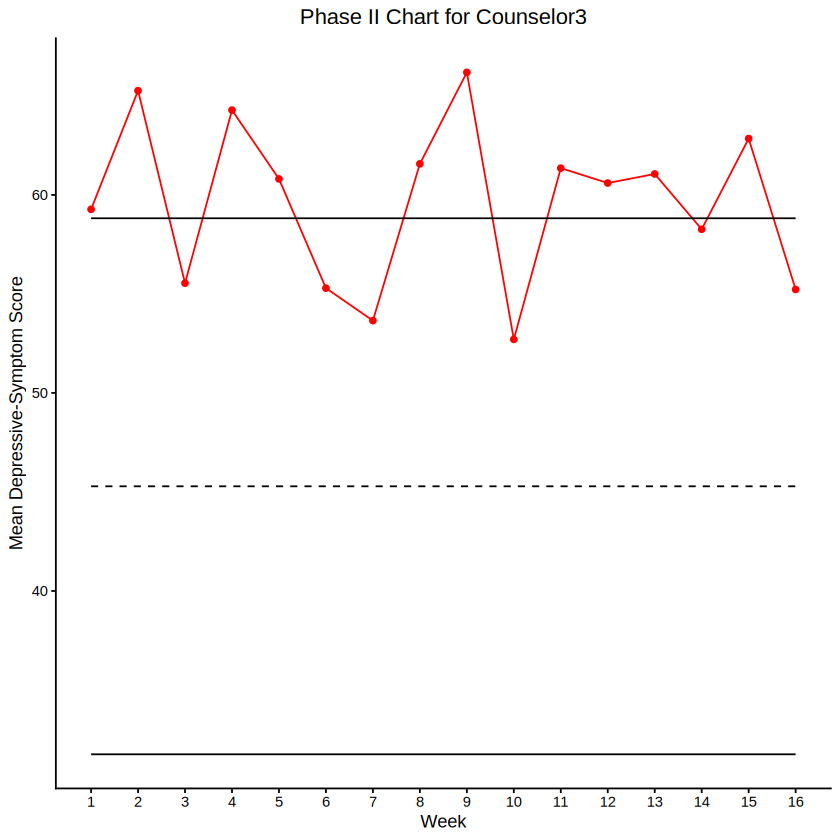

Week
<int>


Week
<int>


Week
<int>
1
2
4
5
8
9
11
12
13


Week
<int>


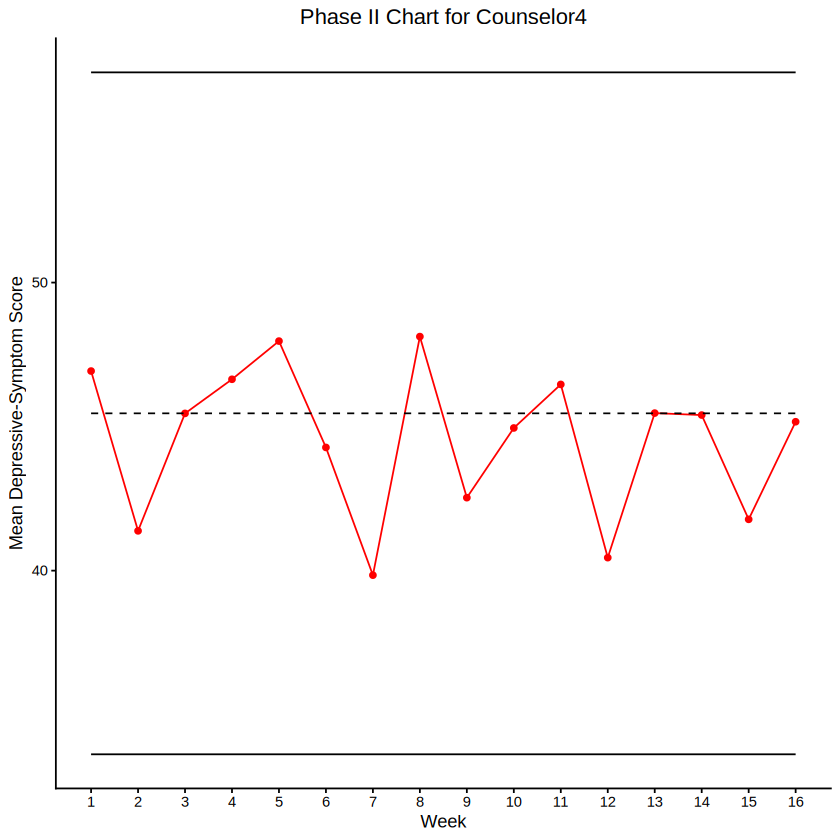

In [19]:
## Q10 Code ##

## Read in Phase II Counselling Data as List ##

sn2 <- excel_sheets("Counselling_PhaseII.xlsx")
sn2

p2 <- lapply(sn2,FUN=function(x){

  d <- read_xlsx("Counselling_PhaseII.xlsx",sheet=x) %>%
    dplyr::select(-`Week`)

  return(d)

})

names(p2) <- paste("Counselor",1:4,sep="")

## Calculate Means ##

samp_list2 <- lapply(names(p2),FUN=function(nm){

  x <- p2[[nm]]

  df <- tibble(Means = rowMeans(x),
               Ranges =
                 apply(x,1,FUN=function(x){

                   max(x) - min(x)

                 }),
               Counselor = nm,
               Week = seq(1,16))

  return(df)

})

names(samp_list2) <- names(p2)

## Plot Phase II Charts ##

cfes2 <- vector('list',length=4)

for(i in 1:4){

  limits <- cfes[[i]]$Limits

  center_line <- cfes[[i]]$Center

  df <- samp_list2[[i]]

  p2_chart <- df |>
    ggplot(aes(x=Week,y=Means)) +
    geom_point(color='red') + geom_line(color='red') +
    geom_line(aes(y=limits[2]),color='black') +
    geom_line(aes(y=limits[1]),color='black') +
    geom_line(aes(y=center_line),color='black',linetype='dashed') +
    labs(x = "Week", y = "Mean Depressive-Symptom Score",
         title = paste("Phase II Chart for ",unique(df$Counselor),sep="")) +
    theme_classic()  +
    theme(plot.title=element_text(hjust=0.50)) +
    scale_x_continuous(breaks = seq(1,16))

  info <- list(Violations = df |>
                 filter(Means > limits[2] | Means < limits[1]) |>
                 select(Week))

  cfes2[[i]] <- info

  print(p2_chart)

}

## So how can we know if any of our points are OOC? ##

cfes2[[1]]

cfes2[[2]]

cfes2[[3]]

cfes2[[4]]

No, we no longer have evidence of statistical control. Applying each counselor's Phase I center line and control limits from Q9 to the spring-semester data, counselor 3 is out of control.

Unlike the Hotelling's T² chart in Q6, the Control Chart for Each Stream approach identified Counselor 3 directly, without a separate post-hoc analysis. Both approaches reach the same conclusion.

### Q11: What is a difference between a multivariate process and a multiple stream process? Given what you found in Q4-Q10, which framing do you think is the more defensible choice for this specific scenario, and why?

A multivariate process involves several quality characteristics that are assumed to be correlated with one another and are monitored jointly. A multiple stream process (MSP) involves several parallel processes producing the same quality characteristic toward a shared target, and the streams are generally assumed to be independent.

For The Owl's Nest, I believe the multivariate framing is the more defensible choice. It allows for control of the overall false alarm rate while taking correlation into account.

### Q12: Provide an overview of your results that you, as the director, could bring to the university's Vice President of Student Affairs. What is the current status of The Owl's Nest program, and what actions (if any) have you taken or would you recommend?

The Owl's Nest was stable during the fall semester, and in the spring three of our four counselors remained consistent, but Counselor 3's clients' average depressive-symptom scores rose by about 14 points (from roughly 45 to 60) starting in the first week and stayed elevated all semester.

I will connect with Counselor 3 to identify the cause and increase their supervision and training